# Лабораторная работа № 3
## Непрерывная оптимизация графов с релаксацией

Дмитрий Андреевич Василенко. Вариант № 7.

Цель работы: добавить выбор структуры в алгоритм подбора модели, используя результаты интервенций из второй лабораторной работы. Для каждой структуры отдельно оцениваем численные параметры, сохраняем сгенерированные графы и выбираем граф по точности, сложности и согласованности с интервенционной диагностикой.

Основа работы: [ЛР № 2 Ивана Папая](https://github.com/papayiv/euler-quadrants-lab/blob/c401635cd8966dec498f17dcff242a3b705fde29/notebooks/lab2_interventions.ipynb). Иван использовал уравнения Эйлера и вычислительный граф из моей первой работы. Из его второй работы берём библиотеку слагаемых, условное перемешивание узлов, блочный бутстреп и правило сохранения элементов графа. Назначенный мне метод генерации графов остаётся № 7.


## 1. Воспроизводимость

Численные эксперименты находятся в `src/graph_lab/experiments.py`, оптимизация и диагностика в `selection.py`, графики в `plotting.py`. Ноутбук показывает сохранённый расчёт. При отсутствии расчёта выполняется команда:

```bash
uv run --locked python scripts/run_lab3.py
```

Та же команда пересчитывает результаты после изменения настроек. Обновить текстовую структуру ноутбука можно через `scripts/build_lab3_notebook.py`. Ранее выполненные лабораторные остаются в своих модулях и ноутбуках.

Исходный модуль Ивана сохранён без изменений в `src/graph_lab/vendor/ivan_interventions.py`. Ссылка на точную версию и сведения об авторстве находятся рядом с модулем. Новый код отдельно реализует вычисления по достаточным статистикам для ускорения повторных проверок.


In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "results" / "lab3"
complete = False
if (OUT / "metrics.json").exists():
    saved = json.loads((OUT / "metrics.json").read_text())
    complete = set(saved.get("datasets", {})) == {"synthetic", "control", "well"} and (OUT / "comparison.png").exists()
if not complete:
    env = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_lab3.py")],
                   cwd=ROOT, env=env, check=True)
metrics = json.loads((OUT / "metrics.json").read_text())
PARAMS = ["a_x", "a_y", "a_z", "bE_x", "bE_y", "bE_z", "bK_x", "bK_y", "bK_z"]
NAMES = {"synthetic": "Эйлер, ANU 6", "control": "Контроль без K в давлении", "well": "The Well"}
METHODS = {"intervention": "с интервенциями", "ablation": "без интервенций"}

def table(headers, rows):
    display(Markdown("\n".join([
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
        *["| " + " | ".join(map(str, row)) + " |" for row in rows],
    ])))

def figure(filename, width=1050):
    path = OUT / filename
    if not path.exists():
        raise FileNotFoundError(f"Пересчитайте эксперименты: отсутствует {path}")
    display(Image(filename=str(path), width=width))

print("Настройки вычислительного эксперимента:")
print(json.dumps(metrics["config"], ensure_ascii=False, indent=2))


Настройки вычислительного эксперимента:
{
  "n_synthetic": 96,
  "n_boot": 100,
  "n_splits": 16,
  "diagnostic_seed": 0,
  "search_seeds": [
    0,
    1,
    2
  ],
  "lambda_complexity": 0.02,
  "lambda_intervention": 0.1,
  "ridge": 1e-05,
  "rounds": 4,
  "steps": 40,
  "samples_per_round": 24,
  "intervention_seed": 1701,
  "selection_rule": "Validation NMSE + lambda_complexity * active_groups/9 + lambda_intervention * training_evidence_disagreement/9",
  "seed_scope": "Search seeds vary gates and graph proposals. Intervention, bootstrap and null-calibration seeds remain fixed.",
  "precommitment": "Splits and default penalties fixed before evaluating test quality. Sensitivity uses validation only."
}


## 2. Модель и пространство графов

Для консервативных переменных $U=(\rho,m_x,m_y,m_z,E)$ используем параметризацию Ивана:

$$
\partial_t U=-\sum_{d\in\{x,y,z\}}\left[
 a_d\partial_d(Uv_d)+\beta^E_d\partial_dP^E_d-\beta^K_d\partial_dP^K_d\right],
\qquad
P^E_d=(0,Ee_d,Ev_d),\quad P^K_d=(0,Ke_d,Kv_d),
$$

где $v_d=m_d/\rho$, $K=\rho\lVert v\rVert^2/2$. При $a_d=1$ и $\beta^E_d=\beta^K_d=\gamma-1$ получаем обычные уравнения Эйлера с давлением $p=(\gamma-1)(E-K)$. Для $\gamma=1.4$ коэффициенты давления равны $0.4$.

Веса по координатам оцениваем независимо, как во второй работе. Равенства $\beta^E_x=\beta^E_y$ и $\beta^K_x=\beta^K_y$ при оценивании не навязываются. Поэтому полученная модель может компенсировать ошибки дискретизации разными коэффициентами по направлениям.

В библиотеке девять групп слагаемых. Бинарная маска $m\in\{0,1\}^9$ включает или исключает соответствующую группу. Это совместный выбор структуры $m$ и параметров $w_m$.

| Группа | Физическая роль | Узел для диагностики |
|---|---|---|
| $a_x,a_y,a_z$ | Адвективный перенос по каждой координате | $u,v,w$ соответственно |
| $\beta^E_x,\beta^E_y,\beta^E_z$ | Вклад полной энергии в давление и работу давления | $E$ |
| $\beta^K_x,\beta^K_y,\beta^K_z$ | Поправка на кинетическую энергию в давлении | $K$ |

Ищем подграфы фиксированной библиотеки операций. Направления зависимостей и сами операции заданы уравнением. Изменение маски не создаёт циклы в вычислительном графе, поэтому отдельный штраф за ацикличность здесь не нужен. Девять групп дают $2^9=512$ возможных масок. Число включённых групп отличается от числа отдельных рёбер исходного графа.

Все доступные данные двумерные. Столбцы трёх $z$-слагаемых нулевые. Их удаление означает, что для этих данных они не оцениваются. Для пространственного течения эту ветвь нужно исследовать заново.


## 3. Данные и разделение выборки

Матрица $X$ содержит сглаженные пространственные производные слагаемых, а $y$ содержит сглаженную временную производную $U$. Временная разность учитывает неравномерные шаги. Уравнения нормируются по RMS отклика, вычисленному только на обучающей части. Те же масштабы применяются к валидации и тесту.

Используются три набора:

1. **Обычная синтетика.** Начальные условия ANU, случай 6, и солвер Русанова из первой работы при $\gamma=1.4$.
2. **Контроль структуры.** Те же начальные условия, но в порождающем солвере давление заменено на $p=(\gamma-1)E$. Вклад $K$ в давление действительно отсутствует в генерации данных.
3. **The Well.** Сохранённая внешняя траектория Clawpack из первой работы. Это численные данные другого солвера. Измеренных физических данных в данном эксперименте нет.

Контроль с $p=(\gamma-1)E$ является искусственной системой законов сохранения. Для него в потоке Русанова и шаге CFL используем собственный спектральный радиус:

$$s_d=\frac{\gamma+1}{2}|v_d|+\sqrt{\frac{(\gamma-1)^2}{4}v_d^2+\frac{\gamma p}{\rho}}.$$

Он соответствует собственным значениям $v_d$ кратности 3 и $(\gamma+1)v_d/2\pm\sqrt{(\gamma-1)^2v_d^2/4+\gamma p/\rho}$. Формула проверена численно по якобиану изменённого потока. Реализация находится в `control_solver.py`; исходный модуль Ивана сохранён отдельно.

На синтетике обучение, валидация и тест используют разные временные участки с промежутками. В The Well есть всего семь кадров. Центры производных разделены, но соседние разностные шаблоны на границах с валидацией используют общие кадры. В частности, валидационный шаблон `[2,3,4]` и тестовый `[4,5,6]` разделяют кадр 4. Тестовый шаблон `[4,5,6]` не пересекается с обучающими `[0,1,2]` и `[1,2,3]`. Поэтому оценку на The Well следует понимать как перенос на более поздний участок одной траектории.

Интервенционная диагностика и её пороги используют только обучающую часть. Валидация выбирает структуру из архива. Тестовые отклики не передаются в оптимизатор.


In [2]:
rows = []
for key, item in metrics["datasets"].items():
    meta = item["metadata"]
    rows.append([
        NAMES[key], "×".join(map(str, meta["grid"])),
        ", ".join(f"{t:.3g}" for t in meta["train_times"]),
        ", ".join(f"{t:.3g}" for t in meta["validation_times"]),
        ", ".join(f"{t:.3g}" for t in meta["test_times"]),
        meta["n_rows"]["train"], meta["n_train_blocks"],
    ])
table(["Набор", "Сетка", "Время обучения", "Валидация", "Тест", "Строк обучения", "Блоков"], rows)


| Набор | Сетка | Время обучения | Валидация | Тест | Строк обучения | Блоков |
| --- | --- | --- | --- | --- | --- | --- |
| Эйлер, ANU 6 | 96×96×1 | 0.03, 0.05, 0.07, 0.09, 0.11, 0.13 | 0.17, 0.19 | 0.25, 0.27, 0.29 | 173280 | 294 |
| Контроль без K в давлении | 96×96×1 | 0.03, 0.05, 0.07, 0.09, 0.11, 0.13 | 0.17, 0.19 | 0.25, 0.27, 0.29 | 173280 | 294 |
| The Well | 64×64×1 | 0.015, 0.03 | 0.06 | 0.12 | 25000 | 98 |

## 4. Критерий Ивана

Проверка каждого слагаемого состоит из двух частей.

**Информативность.** Для линейно-гауссовой модели с подставленной оценкой дисперсии шума используем априорное распределение $w\sim\mathcal N(0,100I)$ и вычисляем

$$I_j=\operatorname{KL}\!\left(p(w_j\mid D_{\rm train})\,\|\,p(w_j)\right).$$

Если $I_j<1$ нат, слагаемое считаем недостаточно информативным по принятому порогу. Это диагностическое правило, а не доказательство неидентифицируемости. Здесь требуется ковариация линейного гауссового распределения параметров. Бутстреп нулевого столбца всегда возвращал бы нулевую оценку и не отражал бы априорную неопределённость.

**Реакция на изменение родителя.** Перемешиваем значения родительского узла внутри бинов плотности. Затем пересчитываем его потомков и регрессоры. Строим распределения оценок весов до и после изменения с помощью блочного бутстрепа и измеряем

$$J_j=\tfrac12\left[\operatorname{KL}(P_j\|Q_j)+\operatorname{KL}(Q_j\|P_j)\right].$$

Это симметризованная KL с множителем $1/2$, как в коде Ивана. Распределения $P_j,Q_j$ представляют гауссовы приближения к бутстреп-распределениям MAP-оценок. Бутстреп-распределение оценок само по себе не является точным байесовским posterior.

Для калибровки порога разбиваем пространственно-временные блоки на две случайные половины без перемешивания родительского узла. 95%-квантиль полученных расстояний обозначим $t_j$. Правило сохранения:

$$q_j=\mathbf1\{I_j\ge1\}\mathbf1\{J_j>t_j\}.$$

Калибровка повторными разбиениями задаёт эмпирический масштаб различий. Она не даёт гарантированного уровня значимости 5% и не учитывает множественные проверки как формальный статистический тест.

Важна интерпретация. Перемешивание меняет входы, а наблюдаемый отклик $\partial_tU$ остаётся прежним. Это диагностика зависимости модели от узла. Она не моделирует физическую эволюцию после $do$-вмешательства. Перемешивание сохраняет эмпирическое распределение выбранного узла внутри каждого бина плотности, но не сохраняет все совместные зависимости и пространственную структуру. Отдельный контроль без $K$ в давлении использует изменение самого порождающего механизма.


## 5. Непрерывная релаксация структуры

Для каждой группы вводим непрерывный коэффициент включения $z_j\in[0,1]$. При фиксированном $z$ обучаем веса:

$$
\widehat w(z)=\arg\min_w\left[
\frac{\lVert y-XD_z w\rVert^2}{s}+\kappa\lVert w\rVert^2\right],
\qquad D_z=\operatorname{diag}(z),\quad s=\lVert y\rVert^2.
$$

Для $\kappa>0$ решение единственно:

$$\widehat w(z)=\left(D_zX^\top XD_z+\kappa sI\right)^{-1}D_zX^\top y.$$

Регуляризация нужна также для непрерывных коэффициентов включения. Без неё можно уменьшать $z_j$ и увеличивать $w_j$ так, чтобы произведение $z_jw_j$ не менялось. Тогда штраф сложности не контролировал бы реальную структуру.

Минимизируем профилированную функцию

$$
F(z;q)=\frac{\lVert y-XD_z\widehat w(z)\rVert^2}{s}
+\kappa\lVert\widehat w(z)\rVert^2
+\lambda\frac1{9}\sum_jz_j
+\eta\frac1{9}\sum_j\left[q_j(1-z_j)+(1-q_j)z_j\right].
$$

$F$ задаёт непрерывный суррогат обучающего критерия генерации. Итоговый критерий $S$, определённый ниже, оценивает дискретные модели на валидации; равенство этих двух целей не предполагается.

Последнее слагаемое штрафует несогласие структуры с интервенционной диагностикой: исключение поддержанного элемента или включение неподдержанного. Сильная реакция на разрушение важного родителя означает, что соответствующую группу нужно сохранить. Поэтому требование «все распределения весов после любого вмешательства должны совпадать» здесь было бы неверным.

В этой реализации устойчивость к интервенциям операционализирована через согласованность выбора структуры с критерием второй работы. Это определение не следует смешивать с физической инвариантностью всех предсказаний.

При фиксированном $q$ производная профилированной функции имеет вид

$$
\frac{\partial F}{\partial z_j}
=\frac{2\widehat w_j}{s}X_j^\top(XD_z\widehat w-y)
+\frac\lambda9+\frac\eta9(1-2q_j).
$$

Производная $\widehat w(z)$ исчезает по условию оптимальности внутренней задачи. Используем L-BFGS-B с ограничениями $0\le z_j\le1$.

Идея непрерывных коэффициентов включения связана с Louizos et al. (2018) и Yamada et al. (2020). В работе реализована собственная детерминированная релаксация на отрезке с последующим семплированием бинарных масок. Она не воспроизводит распределение hard-concrete или алгоритм STG целиком.


## 6. Алгоритм генерации и выбора графов

Начинаем с полной бинарной маски и независимо генерируем $z_j^{(0)}\sim\operatorname{Uniform}(0.35,0.85)$. Выполняем четыре внешних шага, на каждом допускаем до 40 итераций L-BFGS-B. Перед очередной оптимизацией ограничиваем начальные значения отрезком $[0.02,0.98]$, чтобы исключённая группа могла вернуться.

На каждом внешнем шаге:

1. Берём текущую бинарную маску. Для проверки группы $j$ рассматриваем текущую модель с добавленным $j$. Так можно проверить и возвращение ранее исключённого слагаемого.
2. На обучающих данных повторно вычисляем диагностическое решение $q$ для этого контекста. Результат вмешательств входит в следующий шаг изменения структуры.
3. Оптимизируем непрерывные $z$ при фиксированном $q$ и сохраняем траекторию.
4. Получаем бинарные кандидаты пороговой проекцией, выбором $k$ наибольших коэффициентов и семплированием $m_j\sim\operatorname{Bernoulli}(z_j)$. Используем пороги $0.01,0.05,0.1,0.25,0.5,0.75$ и $k=1,\ldots,9$: из-за регуляризации важные непрерывные коэффициенты могут оказаться меньше $0.5$. Сохраняем все генерации, включая повторы.
5. Для каждой маски заново оцениваем веса на обучении и считаем критерий на валидации.

Чтобы сравнение графов разных шагов было согласованным, итоговый критерий использует одну опорную диагностику $q^{\rm ref}$, вычисленную на обучении для полной библиотеки:

$$
S(m)=\underbrace{\frac{\lVert y_{\rm val}-X_{\rm val}D_m\widehat w(m)\rVert^2}
{\lVert y_{\rm val}\rVert^2}}_{\operatorname{NMSE}_{\rm val}}
+\lambda\frac{\lVert m\rVert_0}{9}
+\eta\frac1{9}\sum_j\left[q_j^{\rm ref}(1-m_j)+(1-q_j^{\rm ref})m_j\right].
$$

Адаптивное $q$ управляет генерацией, а фиксированное $q^{\rm ref}$ задаёт общую шкалу отбора. Это различие предотвращает сравнение одних графов по старому порогу, а других по новому.

**Корректность.** При $\kappa>0$ внутренняя линейная задача имеет единственное решение. Ограничения удерживают $z$ в компактном кубе, а все бинарные кандидаты принадлежат разрешённой библиотеке. Удаление групп не создаёт циклов. Алгоритм выбирает минимум критерия среди сохранённых кандидатов. Глобальную оптимальность непрерывной задачи или восстановление истинной причинной структуры это не гарантирует.

Поскольку масок всего 512, отдельно считаем минимум $S$ полным перебором. Он служит проверкой качества поиска. Маска из перебора не подставляется в архив генератора. Нулевой разрыв с перебором подтверждает оптимальность только для данной конечной библиотеки и выбранного критерия.


## 7. Результаты интервенционной диагностики

Ниже приведены опорные решения, полученные на обучающих данных новой работы. Они могут отличаться от чисел Ивана: здесь другая обучающая часть и отдельный отложенный тест.


### Эйлер, ANU 6

| Группа | KL к prior, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.01 | 1.2e+03 | 3.32 | сохранить |
| a_y | 9.05 | 983 | 4.39 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 8.04 | 118 | 1.55 | сохранить |
| bE_y | 8.33 | 41.2 | 4.87 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 7.74 | 8.94 | 2.37 | сохранить |
| bK_y | 7.93 | 1.01 | 4.34 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

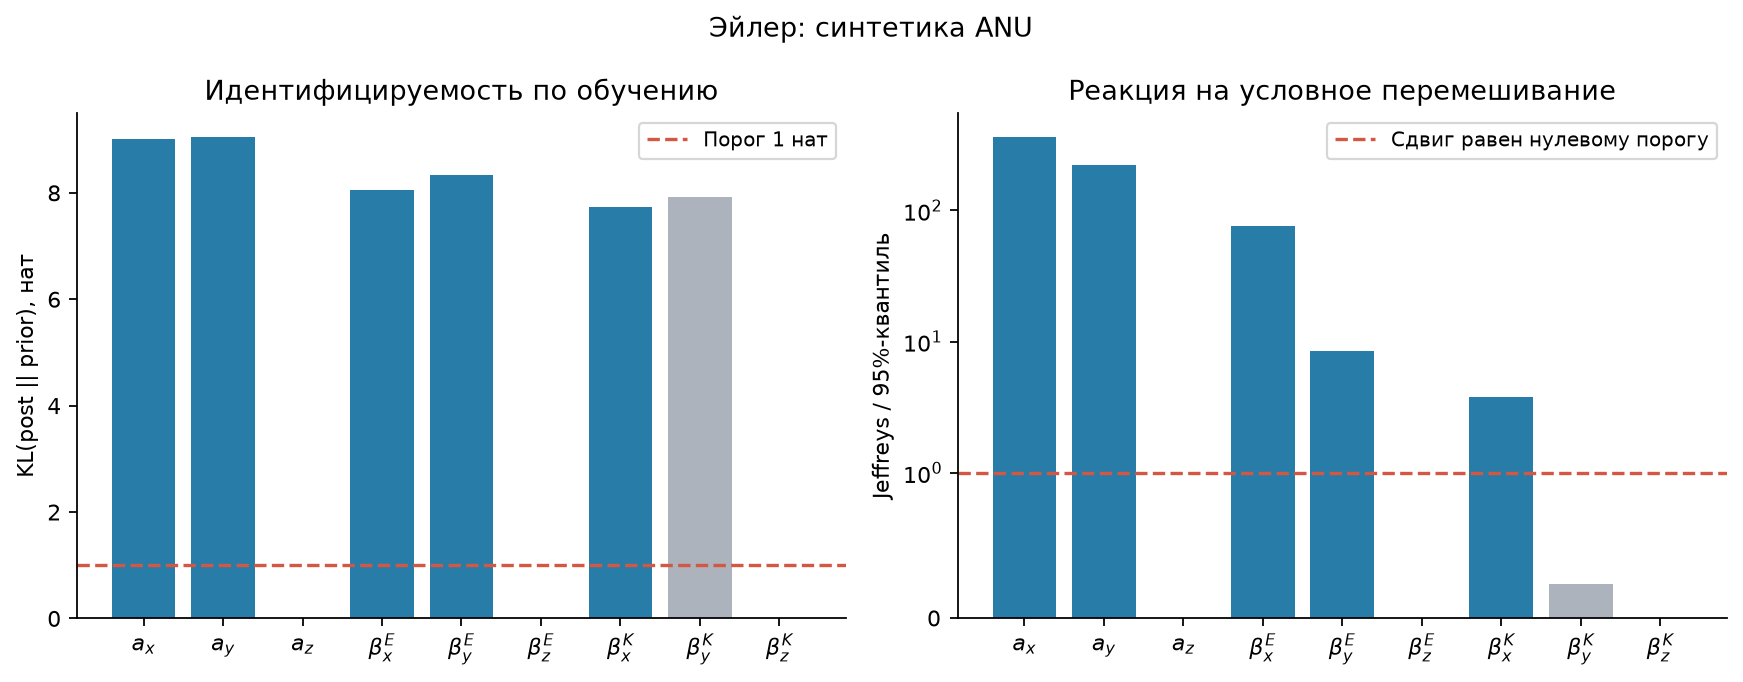

### Контроль без K в давлении

| Группа | KL к prior, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.08 | 874 | 3.26 | сохранить |
| a_y | 8.98 | 701 | 4.45 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 8.11 | 104 | 2.18 | сохранить |
| bE_y | 8.38 | 36.7 | 7.31 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 8.26 | 1.03 | 7.41 | исключить |
| bK_y | 8.49 | 0.0151 | 4.81 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

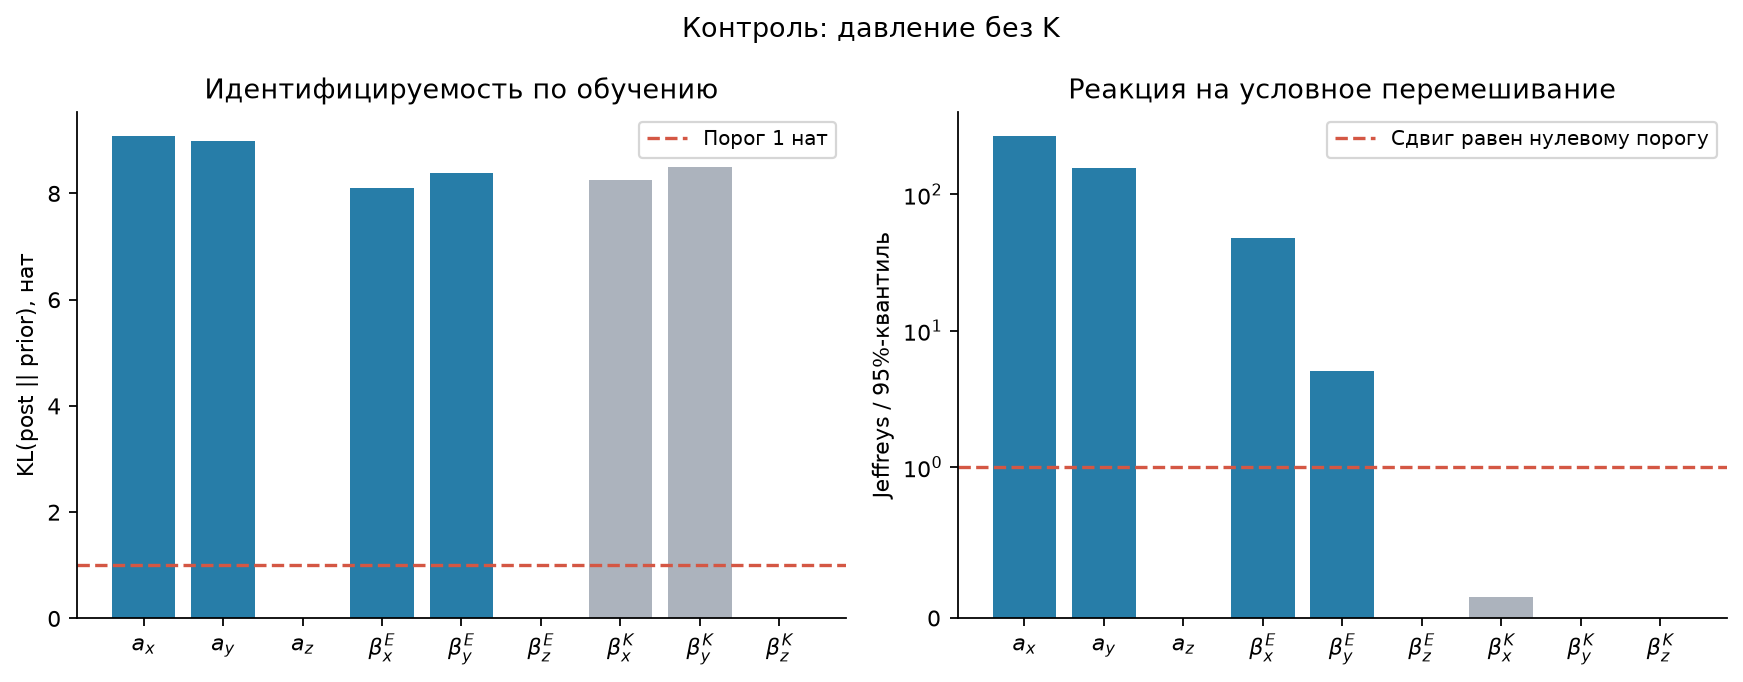

### The Well

| Группа | KL к prior, нат | Сдвиг J | Порог | Решение |
| --- | --- | --- | --- | --- |
| a_x | 9.62 | 8.73e+03 | 3.84 | сохранить |
| a_y | 8.73 | 2.3e+03 | 6.28 | сохранить |
| a_z | 0 | 0 | 0 | исключить |
| bE_x | 9.98 | 326 | 6.06 | сохранить |
| bE_y | 9.36 | 22.6 | 5.77 | сохранить |
| bE_z | 0 | 0 | 0 | исключить |
| bK_x | 8.73 | 27.5 | 8.05 | сохранить |
| bK_y | 7.6 | 6.02 | 10.6 | исключить |
| bK_z | 0 | 0 | 0 | исключить |

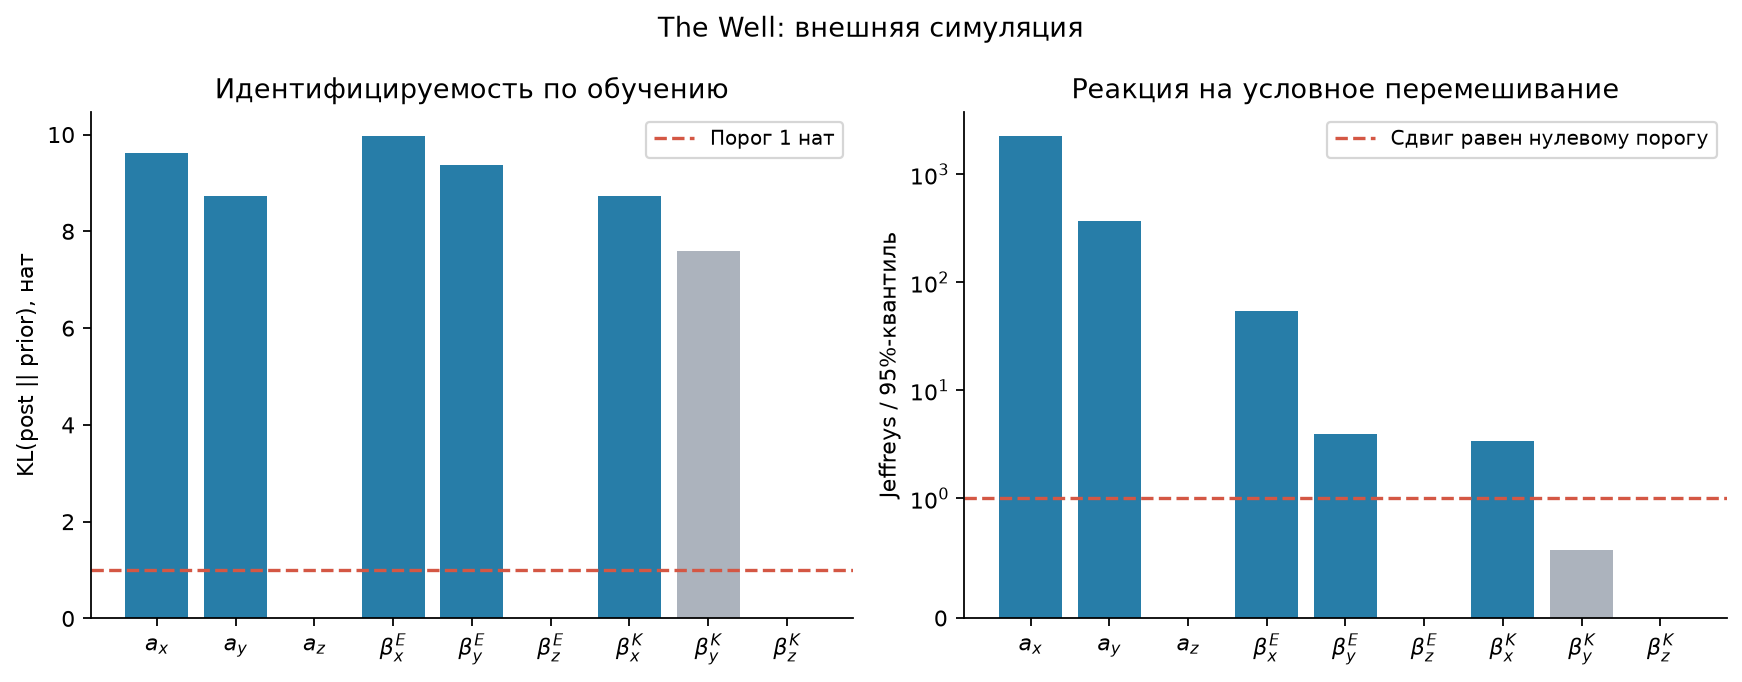

In [3]:
for key, item in metrics["datasets"].items():
    display(Markdown(f"### {NAMES[key]}"))
    d = item["reference_diagnostics"]
    rows = [[PARAMS[j], f"{d['info'][j]:.3g}", f"{d['shift'][j]:.3g}",
             f"{d['null_q'][j]:.3g}", "сохранить" if d["keep"][j] else "исключить"]
            for j in range(9)]
    table(["Группа", "KL к prior, нат", "Сдвиг J", "Порог", "Решение"], rows)
    figure(f"{key}_diagnostics.png")


## 8. Траектория непрерывных коэффициентов и последовательность графов

На траекториях видно, как меняются непрерывные коэффициенты включения. Графы показывают дискретные структуры в ходе поиска. Их узлы обозначают группы операций, поэтому количество нарисованных связей не обязано совпадать с исходным графом из 18 вершин.

Начальная полная библиотека и пустая маска дают контрольные крайние случаи. Непрерывные коэффициенты не следует напрямую трактовать как оценённые вероятности существования физической связи: это параметры оптимизации и распределения предложений.


### Эйлер, ANU 6

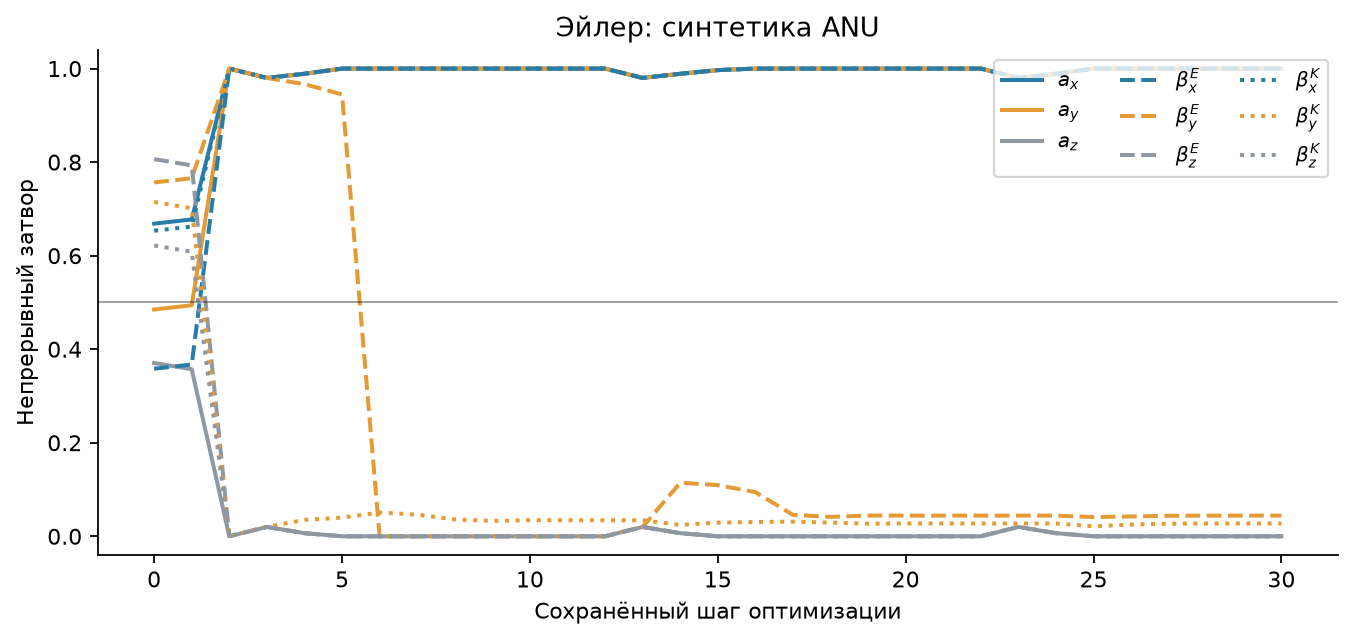

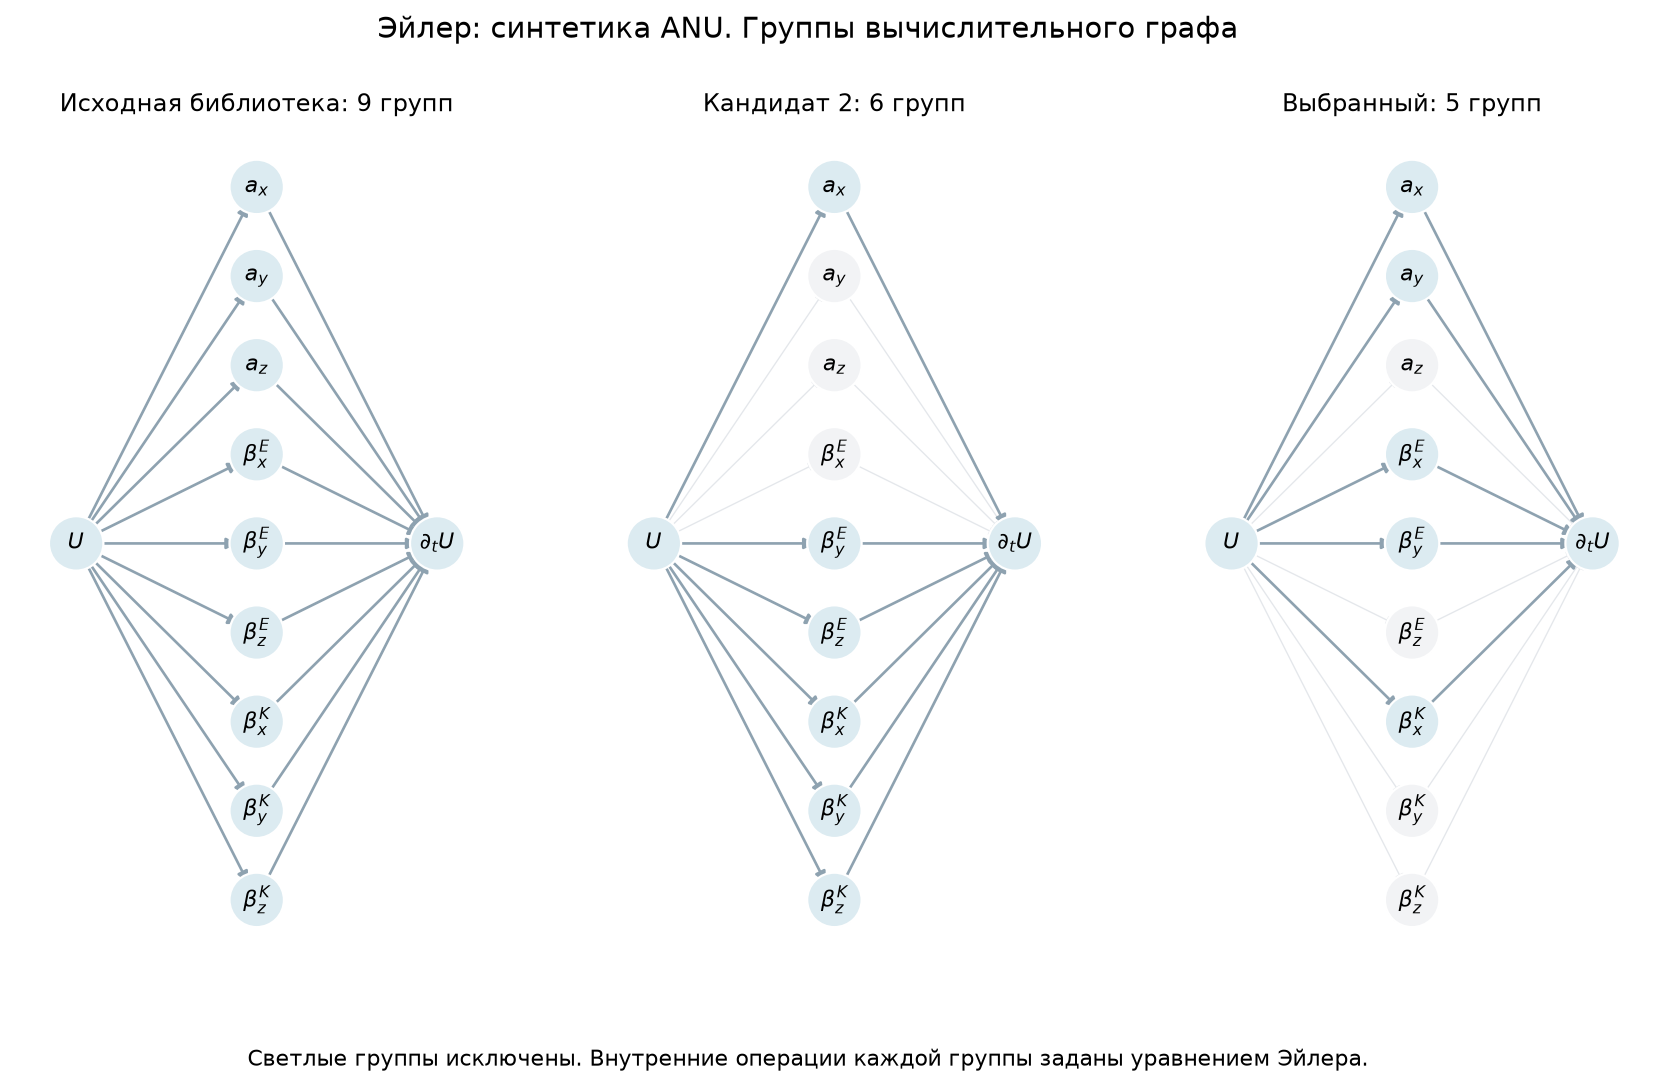

### Контроль без K в давлении

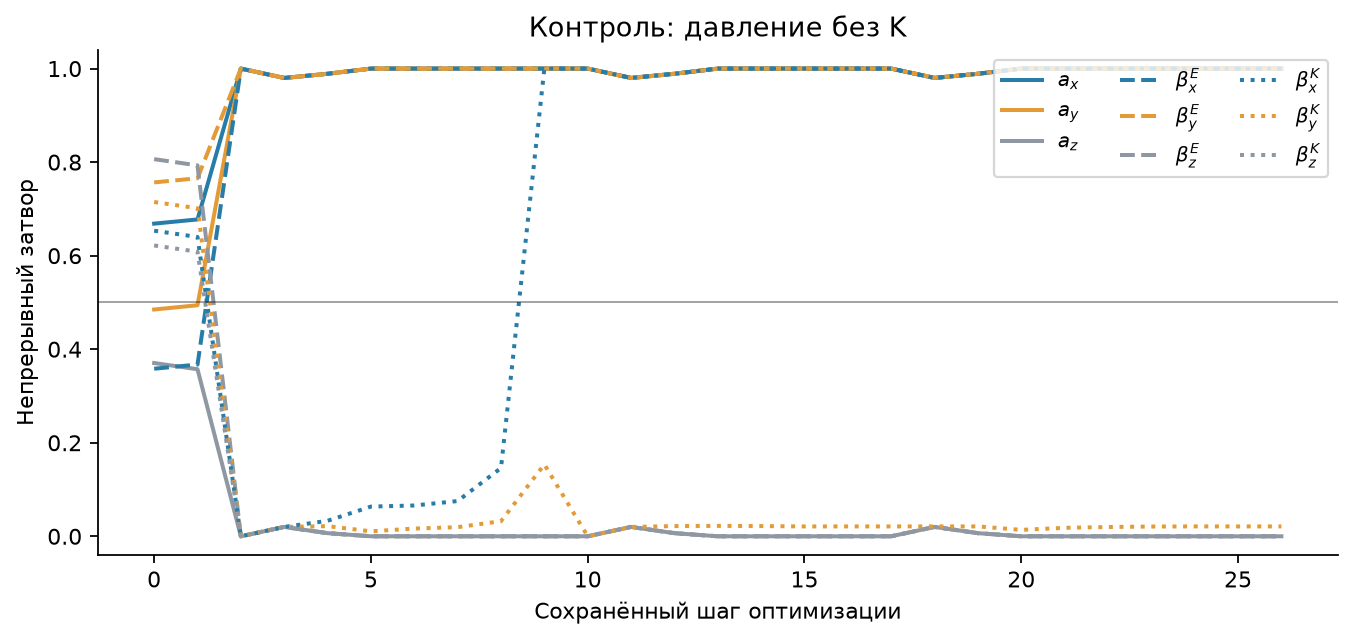

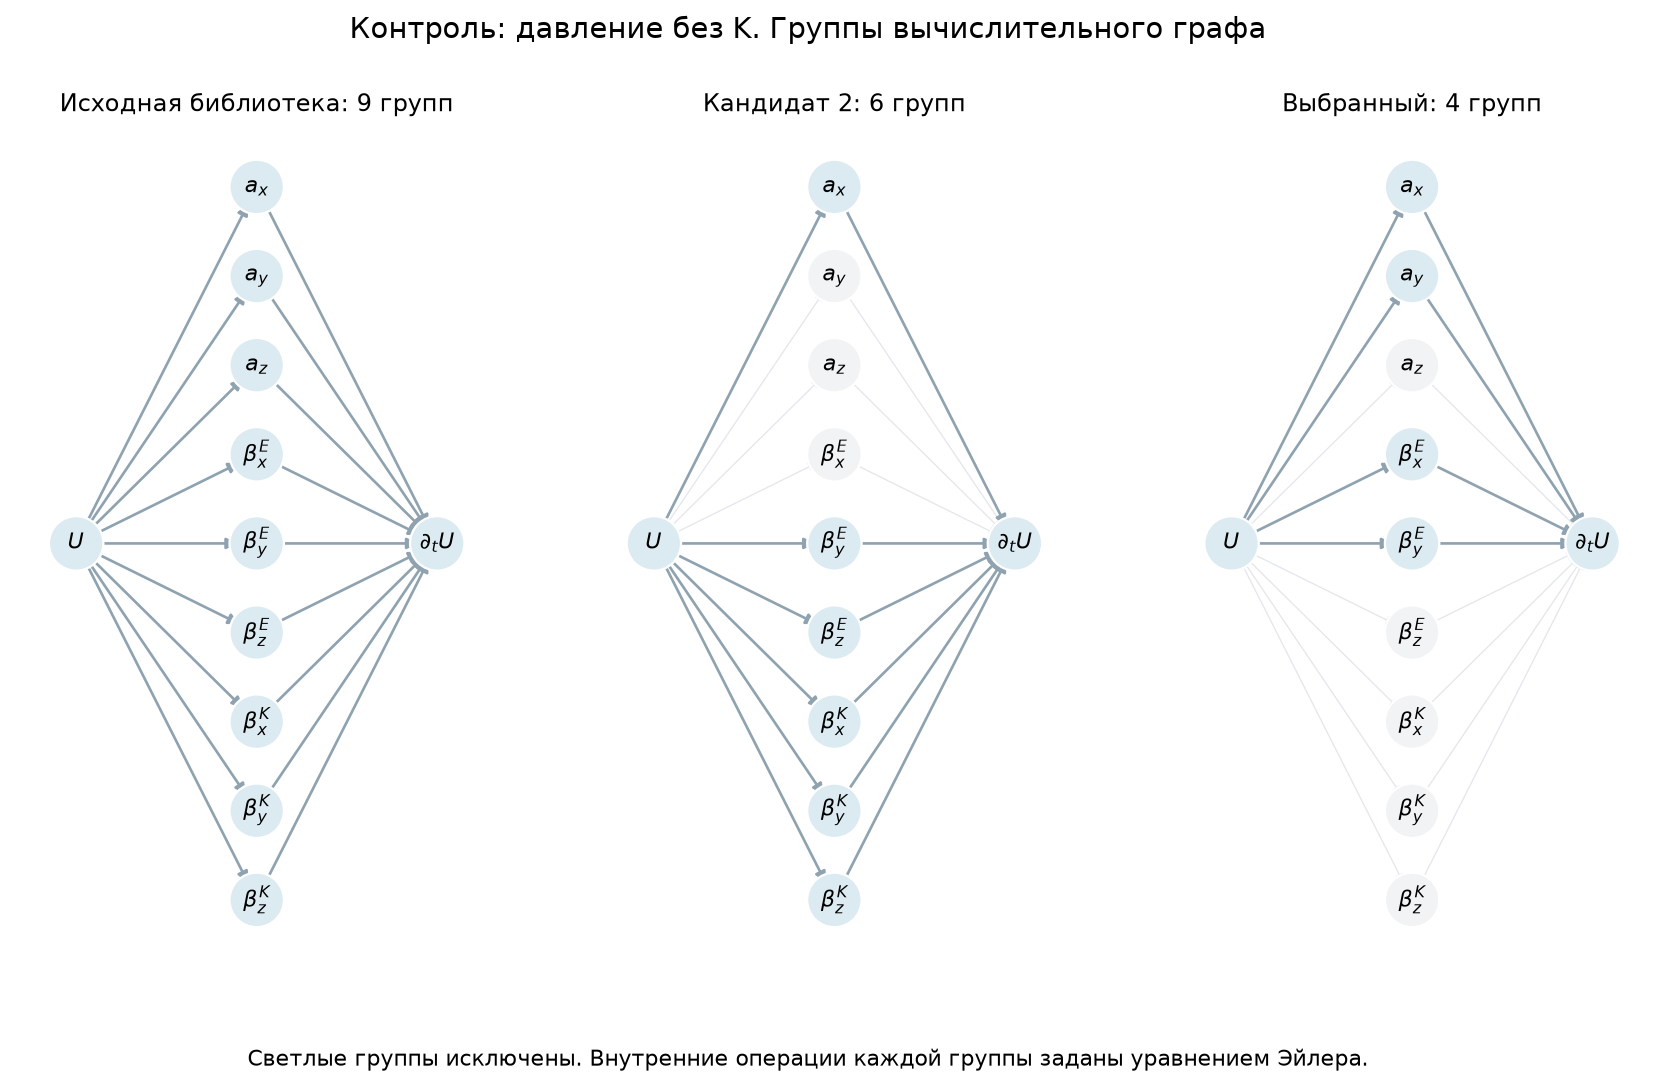

### The Well

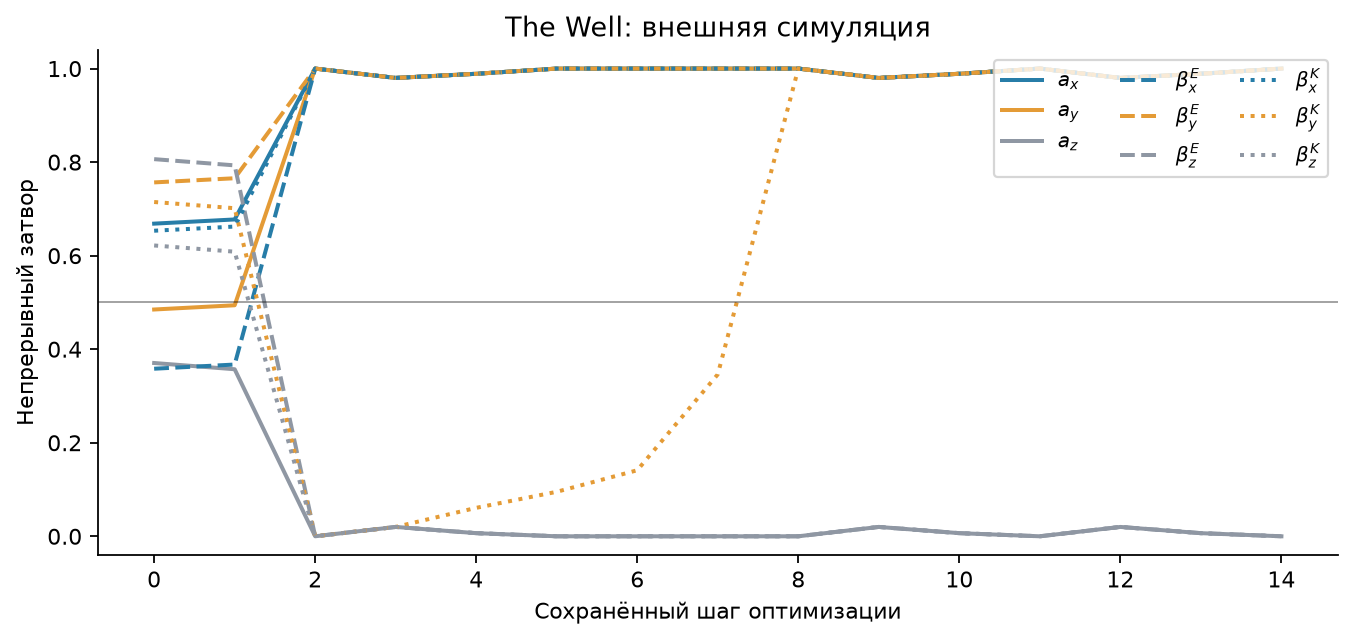

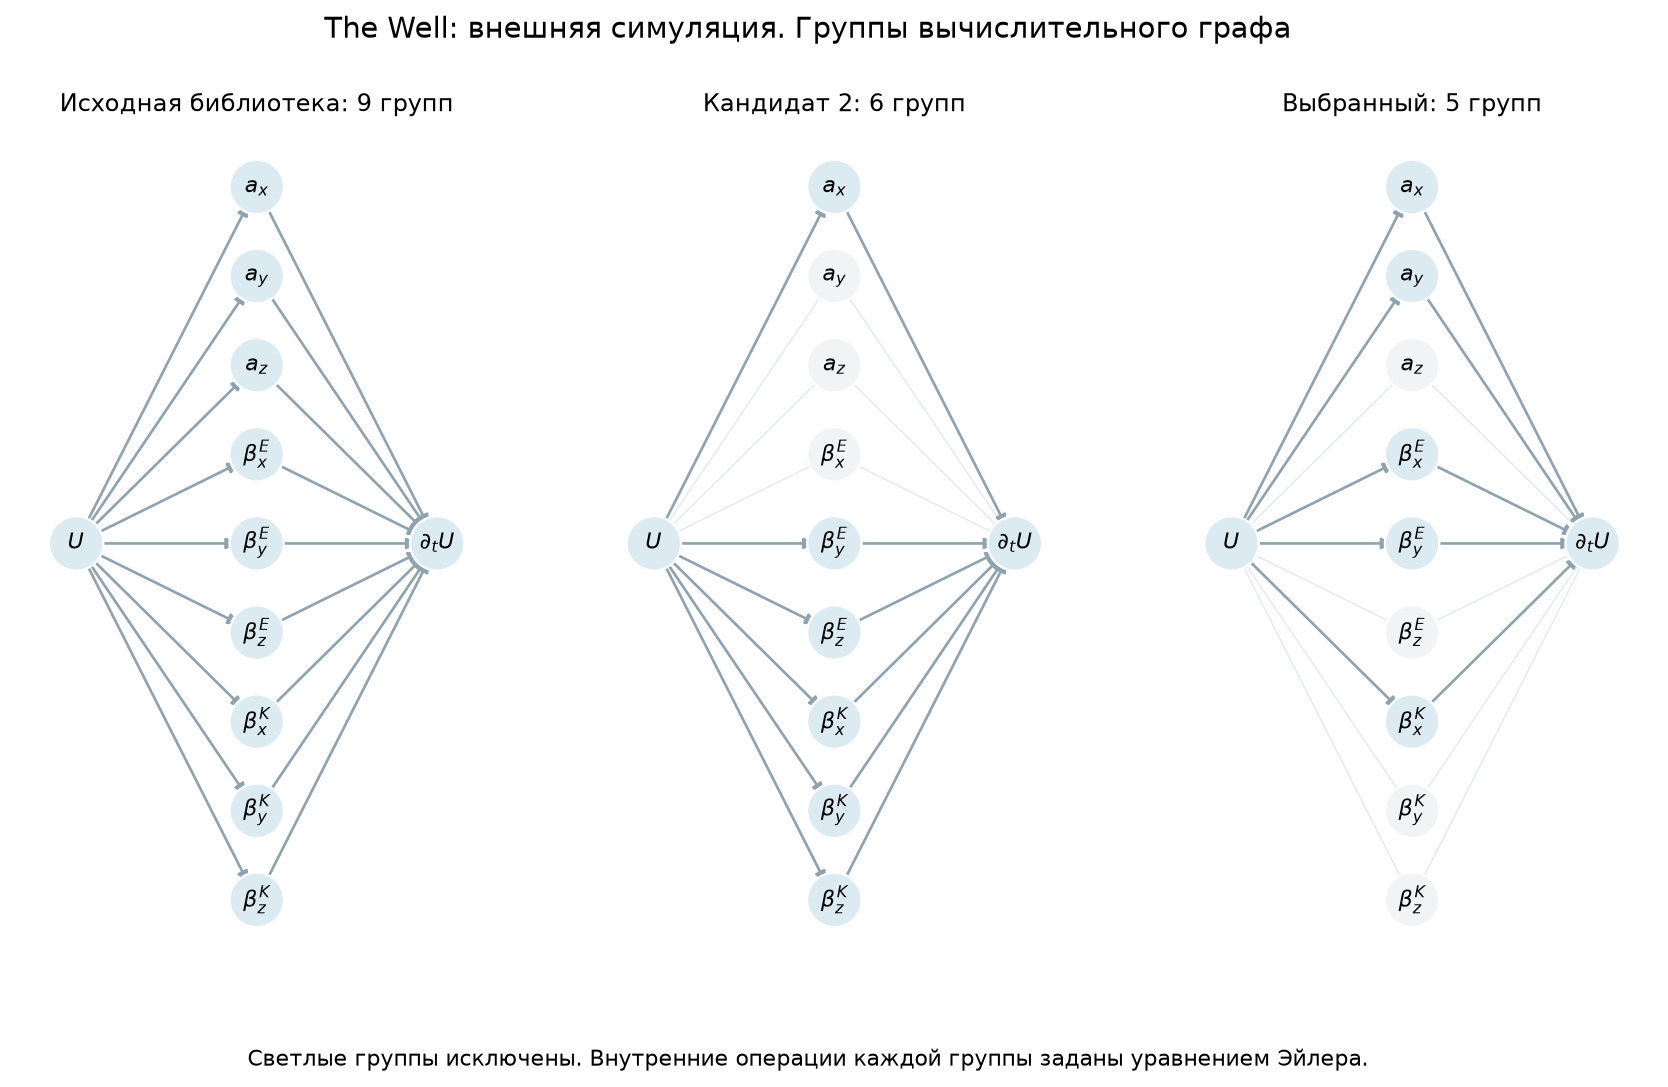

### Обратная связь диагностики на The Well

| Шаг | Текущая маска | Группы с q = 1 | Выбор для следующего шага |
| --- | --- | --- | --- |
| 1 | a_x, a_y, a_z, bE_x, bE_y, bE_z, bK_x, bK_y, bK_z | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x |
| 2 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |
| 3 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |
| 4 | a_x, a_y, bE_x, bE_y, bK_x | a_x, a_y, bE_x, bE_y, bK_x, bK_y | a_x, a_y, bE_x, bE_y, bK_x |

In [4]:
for key in metrics["datasets"]:
    display(Markdown(f"### {NAMES[key]}"))
    figure(f"{key}_gates.png")
    figure(f"{key}_graphs.png")

# Диагностическое решение относится к текущему контексту, а не ко всему архиву.
well_rounds = metrics["datasets"]["well"]["runs"][0]["rounds"]
rows = []
for step in well_rounds:
    before = ", ".join(p for p, on in zip(PARAMS, step["mask_before"]) if on)
    supported = ", ".join(p for p, on in zip(PARAMS, step["diagnostics"]["keep"]) if on)
    after = ", ".join(p for p, on in zip(PARAMS, step["selected_mask"]) if on)
    rows.append([step["round"] + 1, before or "пустая", supported or "нет", after or "пустая"])
display(Markdown("### Обратная связь диагностики на The Well"))
table(["Шаг", "Текущая маска", "Группы с q = 1", "Выбор для следующего шага"], rows)


## 9. Выбор модели и проверка полным перебором

Для каждого запуска показываем маску, число активных групп, валидационную ошибку и разрыв с точным минимумом его собственного критерия. Для варианта без интервенционного слагаемого используется $\eta=0$ и соответствующий ему минимум перебора.

Относительная $L_2$-ошибка равна $\sqrt{\operatorname{NMSE}}$. В таблице она приведена в процентах, а итоговый критерий $S$ остаётся безразмерным.


| Набор | Метод | Seed | Активные группы | Число | L₂ val | L₂ test | S | Разрыв |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Эйлер, ANU 6 | с интервенциями | 0 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | с интервенциями | 1 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | с интервенциями | 2 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 12.95% | 11.14% | 0.02788 | 0 |
| Эйлер, ANU 6 | без интервенций | 0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 6 | 11.95% | 9.35% | 0.02761 | 0 |
| Контроль без K в давлении | с интервенциями | 0 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | с интервенциями | 1 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | с интервенциями | 2 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| Контроль без K в давлении | без интервенций | 0 | a_x, a_y, bE_x, bE_y | 4 | 11.53% | 8.59% | 0.02218 | 0 |
| The Well | с интервенциями | 0 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | с интервенциями | 1 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | с интервенциями | 2 | a_x, a_y, bE_x, bE_y, bK_x | 5 | 10.05% | 10.75% | 0.02120 | 0 |
| The Well | без интервенций | 0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 6 | 9.32% | 9.36% | 0.02203 | 0.000822 |

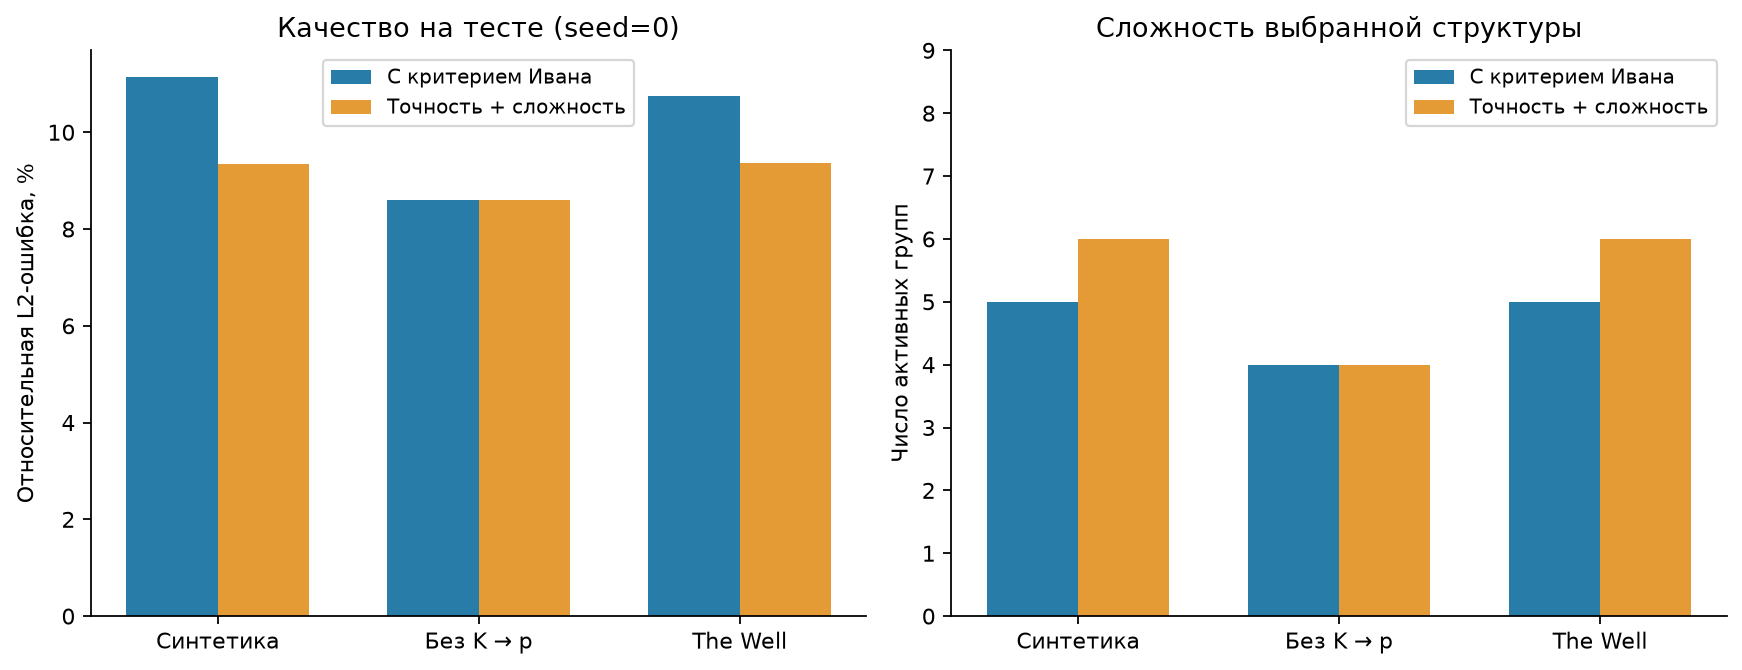

| Коэффициент выбранной модели | Эйлер, ANU 6 | Контроль без K в давлении | The Well |
| --- | --- | --- | --- |
| a_x | 0.97587 | 0.97247 | 1.00563 |
| a_y | 1.00073 | 1.01942 | 0.89821 |
| a_z | 0.00000 | 0.00000 | 0.00000 |
| bE_x | 0.42914 | 0.40484 | 0.39563 |
| bE_y | 0.17747 | 0.35439 | 0.38330 |
| bE_z | 0.00000 | 0.00000 | 0.00000 |
| bK_x | 0.50696 | -0.00000 | 0.40481 |
| bK_y | -0.00000 | 0.00000 | -0.00000 |
| bK_z | 0.00000 | 0.00000 | 0.00000 |

In [5]:
rows = []
for key, item in metrics["datasets"].items():
    for run in item["runs"]:
        mask = np.asarray(run["selected_mask"], dtype=bool)
        rows.append([NAMES[key], METHODS[run["method"]], run["seed"],
                     ", ".join(p for p, on in zip(PARAMS, mask) if on) or "пустая",
                     int(mask.sum()), f"{100*np.sqrt(run['val_nmse']):.2f}%",
                     f"{100*np.sqrt(run['test_nmse']):.2f}%", f"{run['score']:.5f}",
                     f"{run['oracle_gap']:.3g}"])
table(["Набор", "Метод", "Seed", "Активные группы", "Число", "L₂ val", "L₂ test", "S", "Разрыв"], rows)
figure("comparison.png")

rows = [[PARAMS[j], *[f"{item['runs'][0]['coefficients'][j]:.5f}" for item in metrics["datasets"].values()]]
        for j in range(9)]
table(["Коэффициент выбранной модели", *[NAMES[k] for k in metrics["datasets"]]], rows)


Повторные запуски меняют случайность оптимизации и генерации кандидатов при фиксированных данных и настройках диагностики. Совпадение выбранных масок в этих запусках характеризует устойчивость поиска. Оно не является доверительным интервалом для структуры по новым данным.

Тест здесь используется для отчёта о качестве уже выбранных моделей. По тестовым ошибкам не выбирается seed или метод. Основным считается первый заранее заданный запуск с интервенционным слагаемым, остальные показывают воспроизводимость и результат абляции.


Эйлер, ANU 6: различных выбранных масок в трёх запусках = 1
Контроль без K в давлении: различных выбранных масок в трёх запусках = 1
The Well: различных выбранных масок в трёх запусках = 1
Файлы с сохранёнными генерациями и численными результатами:
results/lab3/candidate_graphs.jsonl
results/lab3/control_approximation.npz
results/lab3/metrics.json
results/lab3/synthetic_approximation.npz
results/lab3/well_approximation.npz


### Архив кандидатов: Эйлер, ANU 6

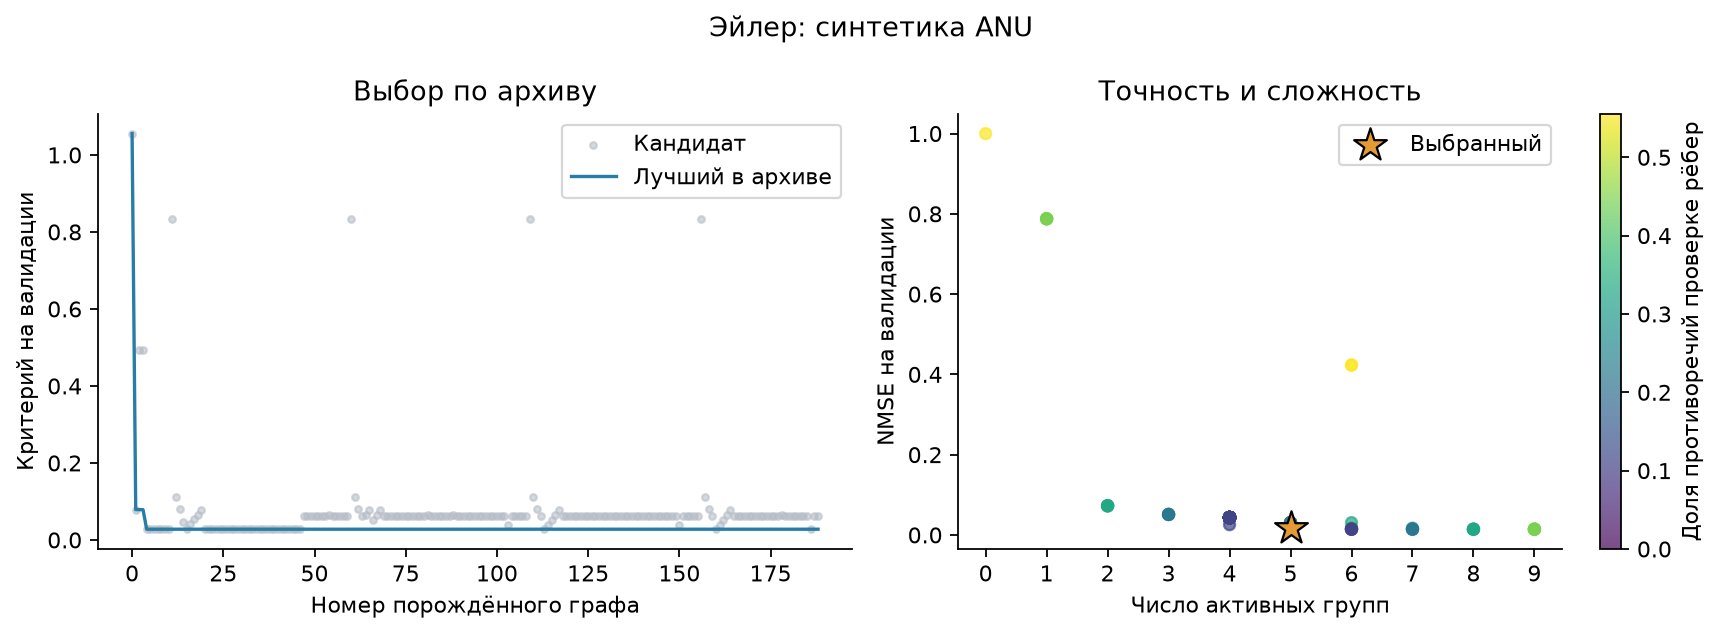

### Архив кандидатов: Контроль без K в давлении

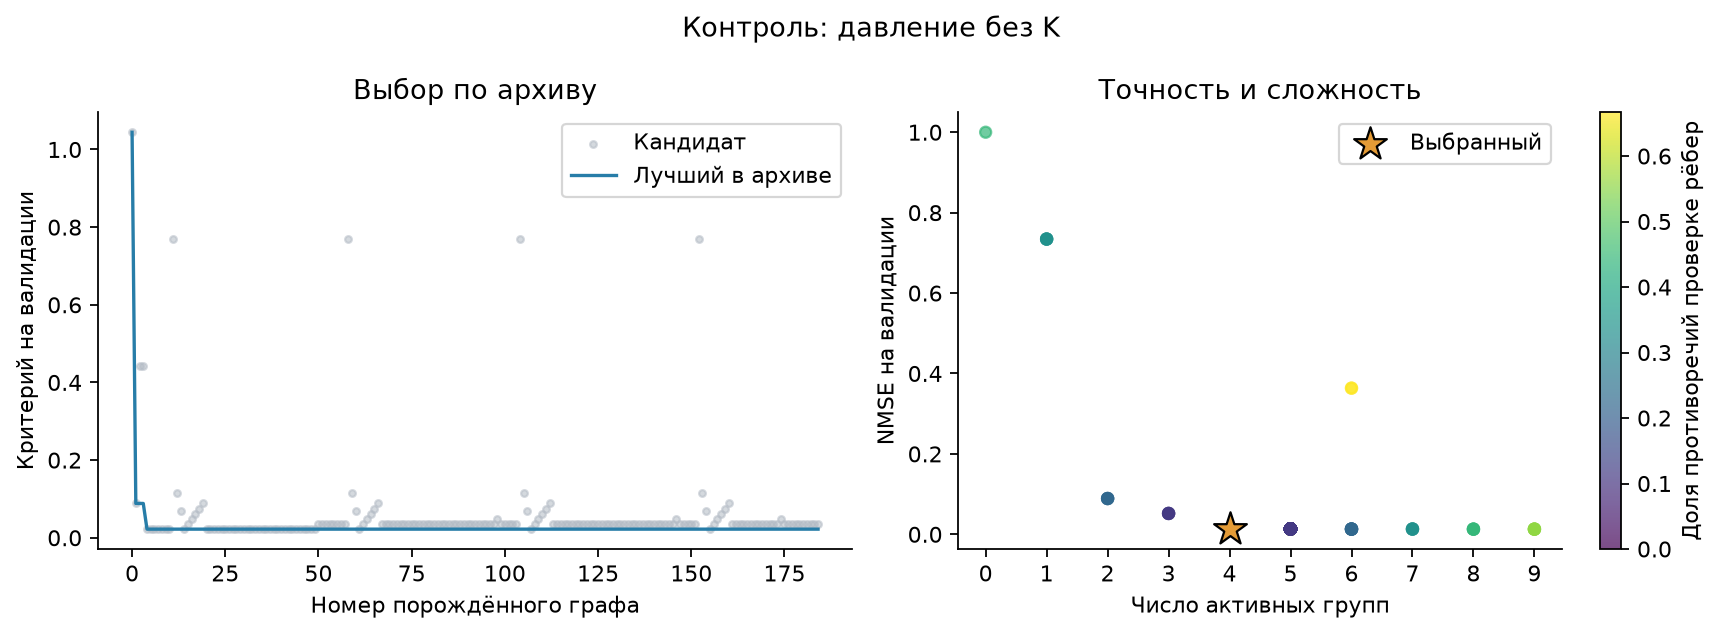

### Архив кандидатов: The Well

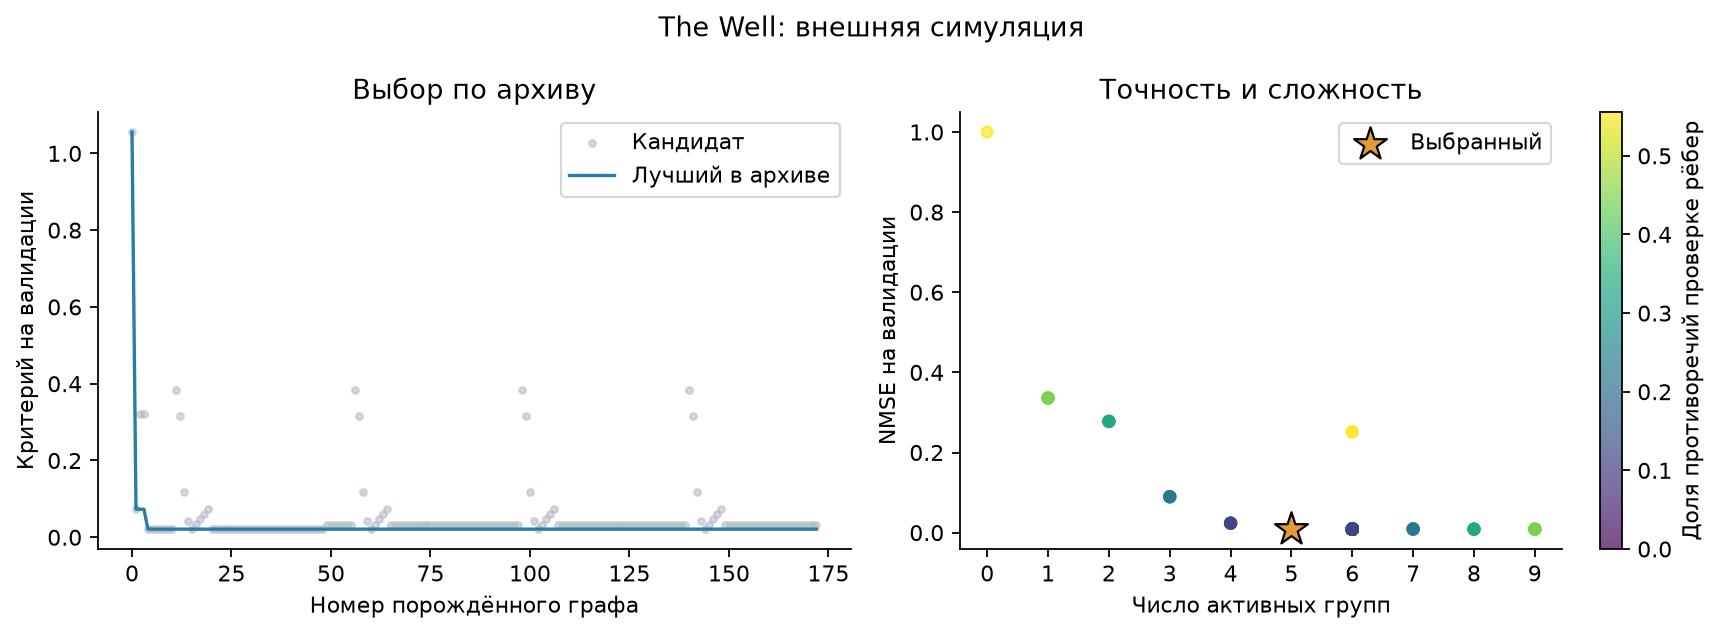

In [6]:
for key, item in metrics["datasets"].items():
    s = item["seed_stability"]
    print(f"{NAMES[key]}: различных выбранных масок в трёх запусках = {s['number_distinct_masks']}")
    display(Markdown(f"### Архив кандидатов: {NAMES[key]}"))
    figure(f"{key}_archive.png")
print("Файлы с сохранёнными генерациями и численными результатами:")
for path in sorted(OUT.iterdir()):
    if path.suffix in {".json", ".jsonl", ".npz"}:
        print(path.relative_to(ROOT))


## 10. Аппроксимация отложенной выборки

Проверяем предсказанную правую часть уравнения, то есть сглаженную $\partial_tU$, на тестовых кадрах. Это проверка локальной модели производных. Длительное интегрирование отобранной модели и устойчивость полученной траектории в этом эксперименте не оцениваются.

На рисунках показаны наблюдаемая величина и предсказание выбранного графа. Общий масштаб нормировки взят из обучающей части. Отличия включают ошибку структуры, оценку коэффициентов, численную диффузию солвера и ошибку конечных разностей.


### Эйлер, ANU 6

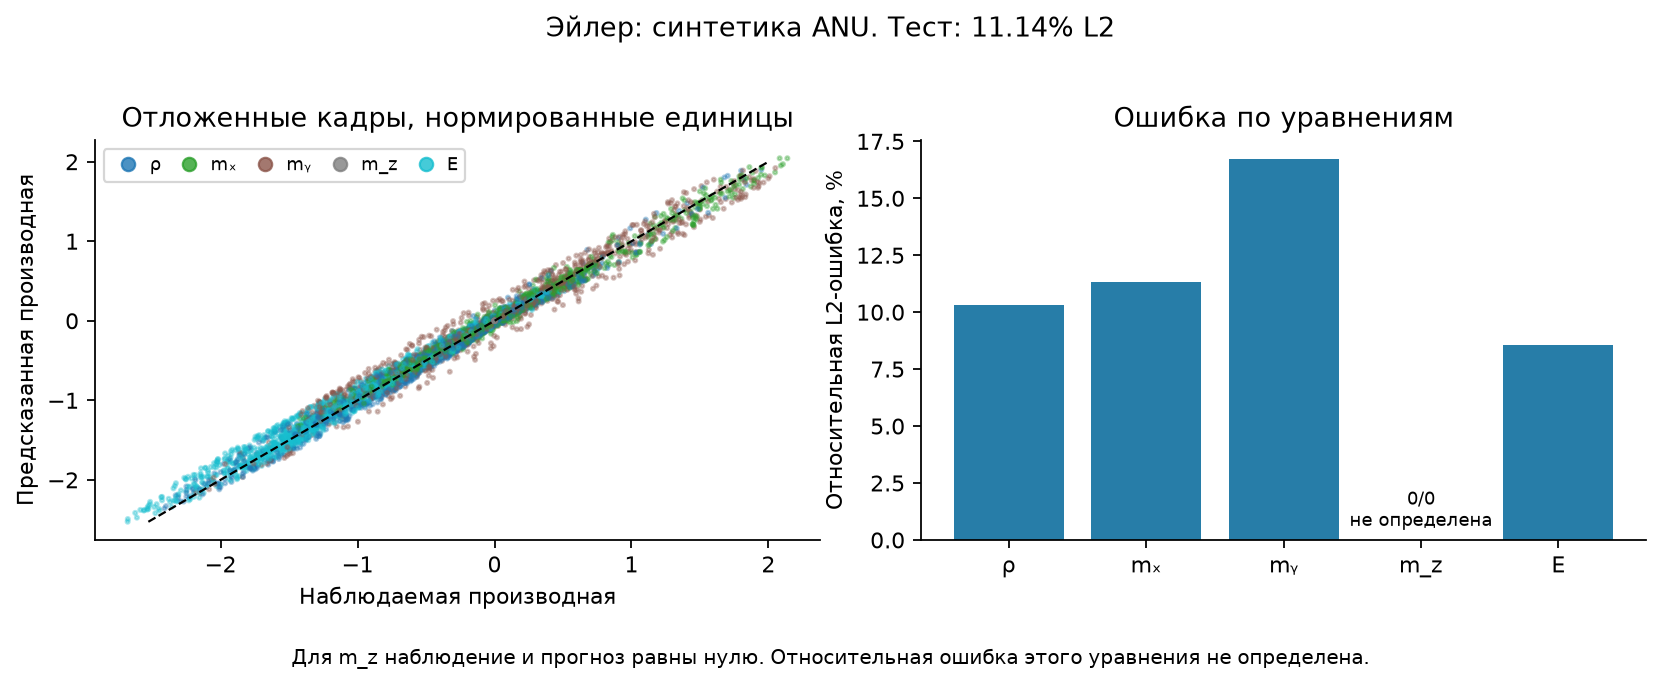

### Контроль без K в давлении

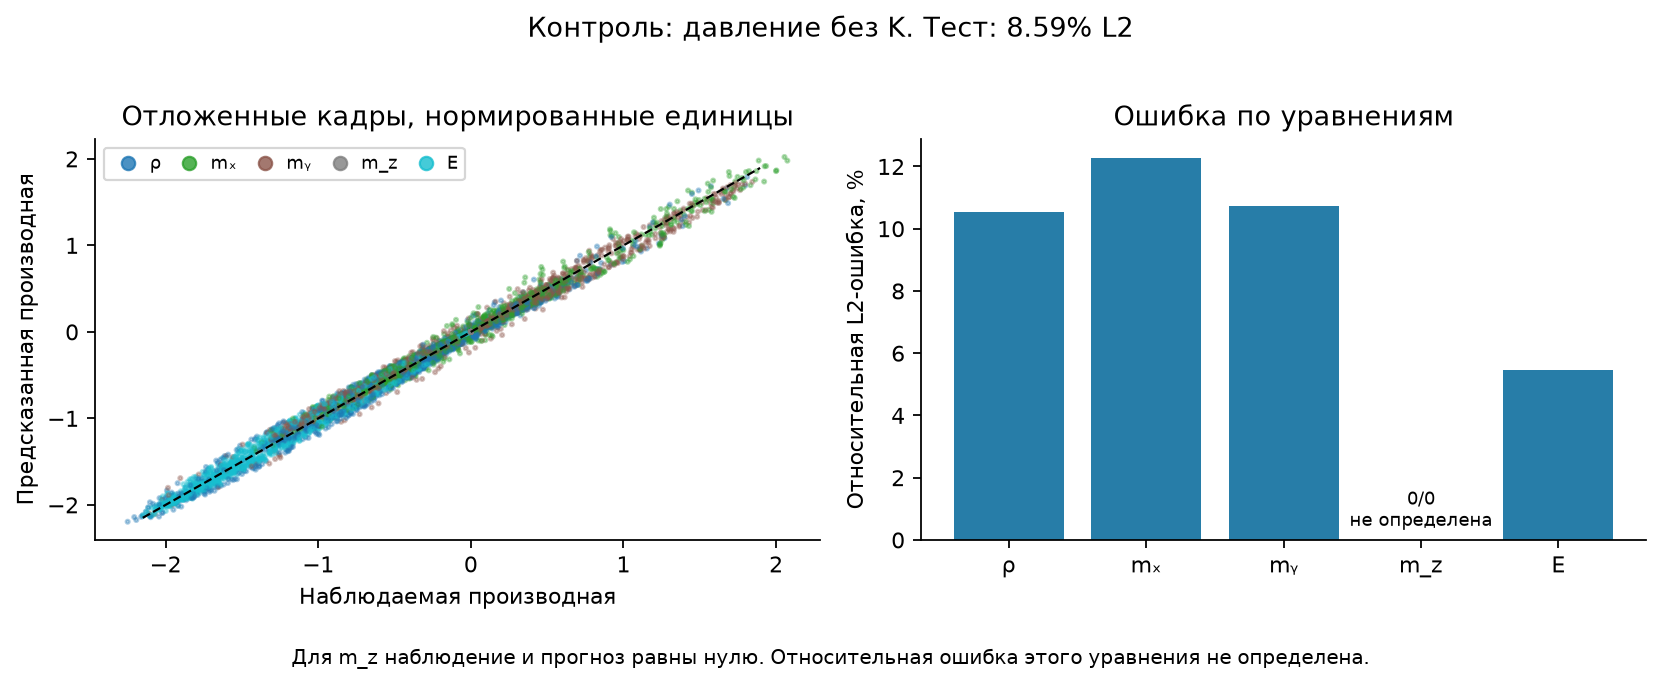

### The Well

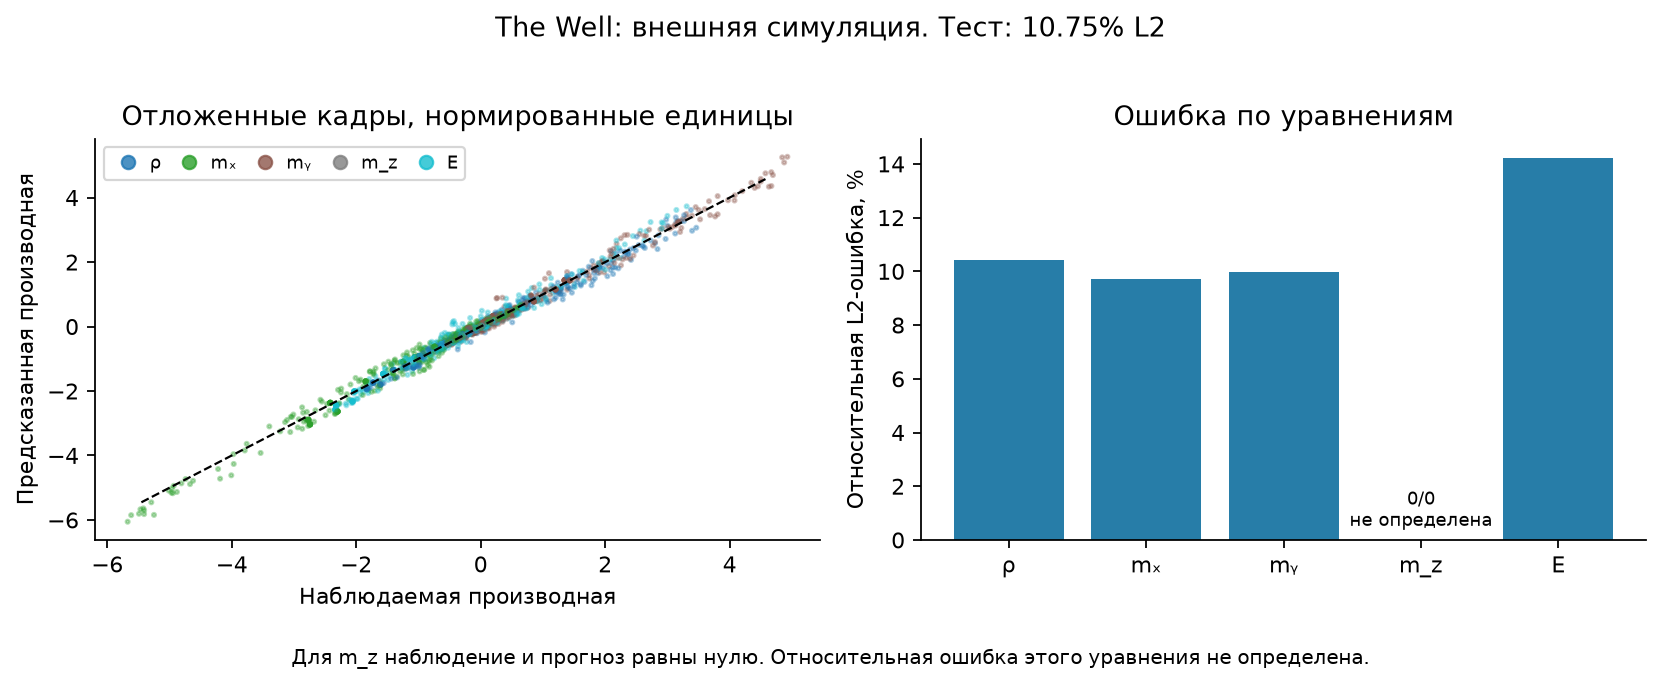

In [7]:
for key in metrics["datasets"]:
    display(Markdown(f"### {NAMES[key]}"))
    figure(f"{key}_fit.png")


## 11. Чувствительность к штрафам

Меняем коэффициенты сложности и интервенционного слагаемого при фиксированных данных и диагностических решениях. Это анализ компромисса между ошибкой и размером графа. В данной проверке пересчитывается ранжирование дискретных моделей. Она не доказывает, что непрерывный генератор при каждой настройке посетил бы тот же архив.

Основные настройки заданы до просмотра тестовых результатов. Таблица чувствительности не используется для их последующей подгонки.


In [8]:
for key, item in metrics["datasets"].items():
    display(Markdown(f"### {NAMES[key]}"))
    rows = [[row["lambda_complexity"], row["lambda_intervention"],
             ", ".join(p for p, on in zip(PARAMS, row["selected_mask"]) if on) or "пустая",
             f"{100*np.sqrt(row['val_nmse']):.2f}%", f"{row['score']:.5f}"]
            for row in item["sensitivity"]["rows"]]
    table(["λ", "η", "Активные группы", "L₂ val", "Критерий"], rows)


### Эйлер, ANU 6

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 11.95% | 0.01761 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.01955 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 11.95% | 0.02761 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.02788 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y | 15.97% | 0.06107 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 12.95% | 0.06122 |

### Контроль без K в давлении

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.01552 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.02218 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y | 11.53% | 0.04885 |

### The Well

| λ | η | Активные группы | L₂ val | Критерий |
| --- | --- | --- | --- | --- |
| 0.005 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x, bK_y | 9.32% | 0.01203 |
| 0.005 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.005 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.005 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.01287 |
| 0.02 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.02 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.02120 |
| 0.08 | 0.0 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.03 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.1 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |
| 0.08 | 0.3 | a_x, a_y, bE_x, bE_y, bK_x | 10.05% | 0.05454 |

## 12. Итоги эксперимента

Следующая сводка составляется из выполненного расчёта. Она отделяет найденную структуру от критериев, по которым эта структура выбрана.


In [9]:
for key, item in metrics["datasets"].items():
    first = item["runs"][0]
    keep = [p for p, on in zip(PARAMS, first["selected_mask"]) if on]
    drop = [p for p, on in zip(PARAMS, first["selected_mask"]) if not on]
    lines = [f"**{NAMES[key]}.** Сохраняются: {', '.join(keep) or 'нет'}. "
             f"Исключаются: {', '.join(drop) or 'нет'}.",
             f"Относительная L₂-ошибка на тесте: {100*np.sqrt(first['test_nmse']):.2f}%. "
             f"Разрыв с минимумом дискретного критерия: {first['oracle_gap']:.3g}."]
    ablation = next(run for run in item["runs"] if run["method"] == "ablation")
    error_main = 100*np.sqrt(first["test_nmse"])
    error_ablation = 100*np.sqrt(ablation["test_nmse"])
    comparison = "увеличилась" if error_main > error_ablation + 1e-8 else ("снизилась" if error_main < error_ablation - 1e-8 else "не изменилась")
    lines.append(f"При добавлении интервенционного слагаемого тестовая ошибка {comparison}: "
                 f"{error_ablation:.2f}% без него и {error_main:.2f}% с ним. "
                 "Это сравнение выполнено после выбора моделей, без перенастройки по тесту.")
    if ablation["oracle_gap"] > 1e-9:
        exact = item["oracle"]["ablation"]
        oracle_support = ", ".join(p for p,on in zip(PARAMS,exact["mask"]) if on)
        lines.append(f"Запуск без интервенционного слагаемого не достиг минимума своего критерия: разрыв {ablation['oracle_gap']:.6f}. "
                     f"Полный перебор выбирает {oracle_support}. Ошибка поиска и ошибка восстановления физической структуры являются разными результатами проверки.")
    if key in {"synthetic", "well"}:
        observable = [0, 1, 3, 4, 6, 7]
        missing = [PARAMS[j] for j in observable if not first["selected_mask"][j]]
        if missing:
            lines.append("В известном уравнении порождающего солвера эти x/y-слагаемые присутствуют, но критерий их исключил: "
                         + ", ".join(missing) + ". Это ложное исключение относительно физической структуры, даже если ошибка аппроксимации мала. "
                         "Поэтому данный результат подтверждает выбор минимума критерия, а не точное восстановление уравнения.")
    if key == "control":
        absent_found = not first["selected_mask"][6] and not first["selected_mask"][7]
        lines.append("Оба слагаемых кинетической поправки исключены, что согласуется с порождающим механизмом."
                     if absent_found else
                     "Часть кинетической поправки сохранена, хотя в порождающем механизме её нет. Это ограничение выбранной диагностики и критерия на данной дискретизации.")
    display(Markdown("\n\n".join(lines)))


**Эйлер, ANU 6.** Сохраняются: a_x, a_y, bE_x, bE_y, bK_x. Исключаются: a_z, bE_z, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 11.14%. Разрыв с минимумом дискретного критерия: 0.

При добавлении интервенционного слагаемого тестовая ошибка увеличилась: 9.35% без него и 11.14% с ним. Это сравнение выполнено после выбора моделей, без перенастройки по тесту.

В известном уравнении порождающего солвера эти x/y-слагаемые присутствуют, но критерий их исключил: bK_y. Это ложное исключение относительно физической структуры, даже если ошибка аппроксимации мала. Поэтому данный результат подтверждает выбор минимума критерия, а не точное восстановление уравнения.

**Контроль без K в давлении.** Сохраняются: a_x, a_y, bE_x, bE_y. Исключаются: a_z, bE_z, bK_x, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 8.59%. Разрыв с минимумом дискретного критерия: 0.

При добавлении интервенционного слагаемого тестовая ошибка не изменилась: 8.59% без него и 8.59% с ним. Это сравнение выполнено после выбора моделей, без перенастройки по тесту.

Оба слагаемых кинетической поправки исключены, что согласуется с порождающим механизмом.

**The Well.** Сохраняются: a_x, a_y, bE_x, bE_y, bK_x. Исключаются: a_z, bE_z, bK_y, bK_z.

Относительная L₂-ошибка на тесте: 10.75%. Разрыв с минимумом дискретного критерия: 0.

При добавлении интервенционного слагаемого тестовая ошибка увеличилась: 9.36% без него и 10.75% с ним. Это сравнение выполнено после выбора моделей, без перенастройки по тесту.

Запуск без интервенционного слагаемого не достиг минимума своего критерия: разрыв 0.000822. Полный перебор выбирает a_x, a_y, bE_x, bE_y, bK_x. Ошибка поиска и ошибка восстановления физической структуры являются разными результатами проверки.

В известном уравнении порождающего солвера эти x/y-слагаемые присутствуют, но критерий их исключил: bK_y. Это ложное исключение относительно физической структуры, даже если ошибка аппроксимации мала. Поэтому данный результат подтверждает выбор минимума критерия, а не точное восстановление уравнения.

Интервенционное слагаемое в проведённом расчёте не улучшило точность на тесте: на обычной синтетике и The Well ошибка выросла, а в контроле осталась прежней. В контрольной задаче оба подхода исключили отсутствующие кинетические слагаемые. Это отрицательный результат для улучшения точности, который не отменяет реализации требуемого цикла выбора структуры.

В работе реализован цикл выбора структуры: диагностика элементов, непрерывное обновление коэффициентов включения, получение бинарных графов, оценивание их параметров и отбор из сохранённой выборки. Интервенционный критерий участвует в генерации следующей структуры и в итоговом отборе.

Ограничения вывода:

- Изучается заданная библиотека групп уравнения Эйлера. Произвольные причинные графы между наблюдаемыми переменными не восстанавливаются.
- Перемешивание входов при прежнем отклике проверяет чувствительность модели. Для вывода о физических причинных эффектах потребовались бы дополнительные предположения и данные.
- Отбор на двумерных данных не проверяет необходимость $z$-ветви в трёхмерной системе.
- Гауссовое сглаживание и конечные разности дают приближённую регрессионную задачу. Это не полная реализация интегральной схемы WSINDy.
- Порог бутстреп-диагностики эмпирический. Ошибки дискретизации и корреляции блоков могут влиять на него.
- The Well является внешней численной симуляцией. Если пункт задания о реальных данных требует физических измерений, этот пункт нужно дополнить таким набором.
- Согласие с минимумом перебора относится к выбранному критерию. Оно не доказывает истинность найденной структуры.


## Источники

1. И. Папай. [Лабораторная работа № 2 и исходный код](https://github.com/papayiv/euler-quadrants-lab/tree/c401635cd8966dec498f17dcff242a3b705fde29), 2026. Библиотека слагаемых, интервенционная диагностика и контроль без кинетической поправки.
2. C. Louizos, M. Welling, D. P. Kingma. [Learning Sparse Neural Networks through $L_0$ Regularization](https://arxiv.org/abs/1712.01312). ICLR, 2018. Непрерывные коэффициенты включения для структурной регуляризации.
3. Y. Yamada, O. Lindenbaum, S. Negahban, Y. Kluger. [Feature Selection using Stochastic Gates](https://proceedings.mlr.press/v119/yamada20a.html). ICML, 2020. Релаксация бинарного выбора признаков.
4. C. Strobl et al. [Conditional variable importance for random forests](https://doi.org/10.1186/1471-2105-9-307). BMC Bioinformatics, 2008. Условное перемешивание как средство оценки важности переменной.
5. H. R. Künsch. *The jackknife and the bootstrap for general stationary observations*. Annals of Statistics 17(3), 1217–1241, 1989. Бутстреп зависимых наблюдений.
6. D. A. Messenger, D. M. Bortz. [Weak SINDy for partial differential equations](https://doi.org/10.1016/j.jcp.2021.110525). Journal of Computational Physics, 2021. Контекст слабых форм идентификации PDE.
7. R. Ohana et al. [The Well: a Large-Scale Collection of Diverse Physics Simulations for Machine Learning](https://arxiv.org/abs/2412.00568), 2024. Внешняя численная траектория.
8. R. Liska, B. Wendroff. *Comparison of several difference schemes on 1D and 2D test problems for the Euler equations*. SIAM Journal on Scientific Computing, 2003. [Начальные условия ANU / Fyris](https://www.mso.anu.edu.au/fyris/lw2driemann.html).
9. В. В. Стрижов. Материалы лабораторной работы № 3 и пояснение от 4 ноября 2026 года. Выбор структуры причинно-следственной модели в цикле порождения и выбора моделей.
